In [ ]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import os

print(os.path.getsize('/content/Online Retail.xlsx'))
print(os.path.isfile('/content/Online Retail.xlsx'))

23715344
True


In [ ]:
!file "/content/Online Retail.xlsx

/bin/bash: -c: line 1: unexpected EOF while looking for matching `"'


In [ ]:
import zipfile

file_path = '/content/Online Retail.xlsx'

print("Is Excel file valid:", zipfile.is_zipfile(file_path))

with open(file_path, 'rb') as f:
    print("File starting bytes:", f.read(10))

Is Excel file valid: True
File starting bytes: b'PK\x03\x04\x14\x00\x06\x00\x08\x00'


In [ ]:
!pip install -q openpyxl

import pandas as pd

df = pd.read_excel(
    '/content/Online Retail.xlsx',
    engine='openpyxl'
)

print("Dataset loaded successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Total Rows: 541909
Total Columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [ ]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [ ]:
# Check duplicate records
print("Duplicate Rows:", df.duplicated().sum)

Duplicate Rows: <bound method Series.sum of 0         False
1         False
2         False
3         False
4         False
          ...  
541904    False
541905    False
541906    False
541907    False
541908    False
Length: 541909, dtype: bool>


In [ ]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [ ]:
# Check duplicate rows

print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 5268


In [ ]:
# Check negative values

print("Negative Quantity:",
      (df['Quantity'] < 0).sum())

print("Negative UnitPrice:",
      (df['UnitPrice'] < 0).sum())

Negative Quantity: 10624
Negative UnitPrice: 2


In [ ]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [ ]:
# Remove duplicate rows
df_clean = df.drop_duplicates()

# Remove invalid negative UnitPrice
df_clean = df_clean[df_clean['UnitPrice'] > 0]

# Remove rows with missing Description
df_clean = df_clean.dropna(subset=['Description'])

print("Data Cleaning Completed!")

print("Total Rows:", df_clean.shape[0])
print("Total Columns:", df_clean.shape[1])

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

Data Cleaning Completed!
Total Rows: 534129
Total Columns: 8

Missing Values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132565
Country             0
dtype: int64

Duplicate Rows:
0


In [ ]:
# Check data types

print("Data Types:")
print(df_clean.dtypes)

Data Types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [ ]:
# Convert InvoiceDate to datetime

df_clean['InvoiceDate'] = pd.to_datetime(
    df_clean['InvoiceDate']
)

# Create new features

df_clean['Year'] = df_clean['InvoiceDate'].dt.year
df_clean['Month'] = df_clean['InvoiceDate'].dt.month

# Calculate total sales

df_clean['TotalSales'] = (
    df_clean['Quantity'] * df_clean['UnitPrice']
)

display(df_clean.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Year,Month,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010,12,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010,12,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010,12,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010,12,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010,12,20.34


In [ ]:
# Check outliers using IQR method

Q1 = df_clean['UnitPrice'].quantile(0.25)
Q3 = df_clean['UnitPrice'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean['UnitPrice'] < lower) |
    (df_clean['UnitPrice'] > upper)
]

print("Number of Outliers:", len(outliers))

Number of Outliers: 39448


In [ ]:
print("Final Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

display(df_clean.head())

Final Dataset Shape: (534129, 11)

Missing Values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132565
Country             0
Year                0
Month               0
TotalSales          0
dtype: int64

Duplicate Rows:
0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Year,Month,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010,12,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010,12,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010,12,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010,12,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010,12,20.34


In [ ]:
df_clean.to_csv('clean_dataset.csv', index=False)

print("Clean Dataset Exported Successfully!")

Clean Dataset Exported Successfully!


In [ ]:
from google.colab import files

files.download('clean_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [1]:
from google.colab import files

uploaded = files.upload()

Saving clean_dataset.csv to clean_dataset.csv


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv('clean_dataset.csv')

print("Cleaned Dataset Loaded Successfully!")

Cleaned Dataset Loaded Successfully!


In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Year,Month,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010,12,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010,12,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010,12,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010,12,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010,12,20.34


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 534129 entries, 0 to 534128
Data columns (total 11 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    534129 non-null  object 
 1   StockCode    534129 non-null  object 
 2   Description  534129 non-null  object 
 3   Quantity     534129 non-null  int64  
 4   InvoiceDate  534129 non-null  object 
 5   UnitPrice    534129 non-null  float64
 6   CustomerID   401564 non-null  float64
 7   Country      534129 non-null  object 
 8   Year         534129 non-null  int64  
 9   Month        534129 non-null  int64  
 10  TotalSales   534129 non-null  float64
dtypes: float64(3), int64(3), object(5)
memory usage: 44.8+ MB


In [5]:
df.describe()

,Quantity,UnitPrice,CustomerID,Year,Month,TotalSales
count,534129.000000,534129.000000,401564.000000,534129.000000,534129.000000,534129.000000
mean,9.916818,4.695864,15281.266797,2010.921910,7.547491,18.250518
std,216.452113,95.079189,1713.978947,0.268313,3.508471,380.945385
min,-80995.000000,0.001000,12346.000000,2010.000000,1.000000,-168469.600000
25%,1.000000,1.250000,13939.000000,2011.000000,5.000000,3.750000
50%,3.000000,2.100000,15145.000000,2011.000000,8.000000,9.900000
75%,10.000000,4.130000,16788.000000,2011.000000,11.000000,17.570000
max,80995.000000,38970.000000,18287.000000,2011.000000,12.000000,168469.600000


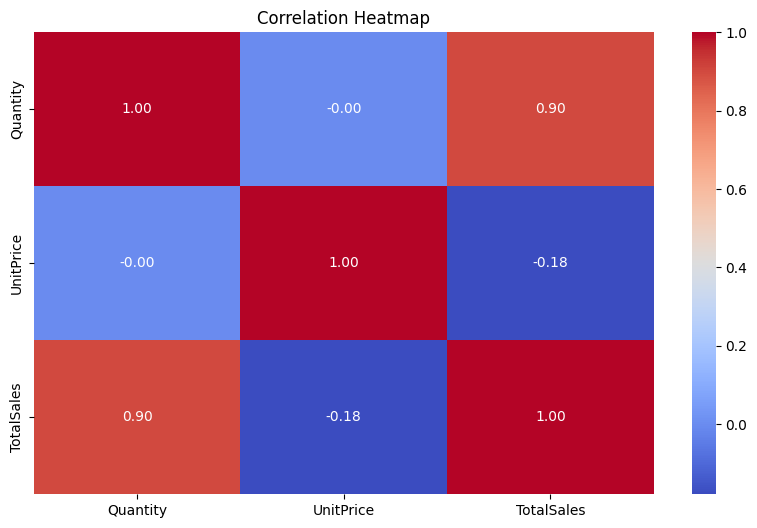

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

corr = df[['Quantity', 'UnitPrice', 'TotalSales']].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm',
            fmt='.2f')

plt.title("Correlation Heatmap")
plt.show()

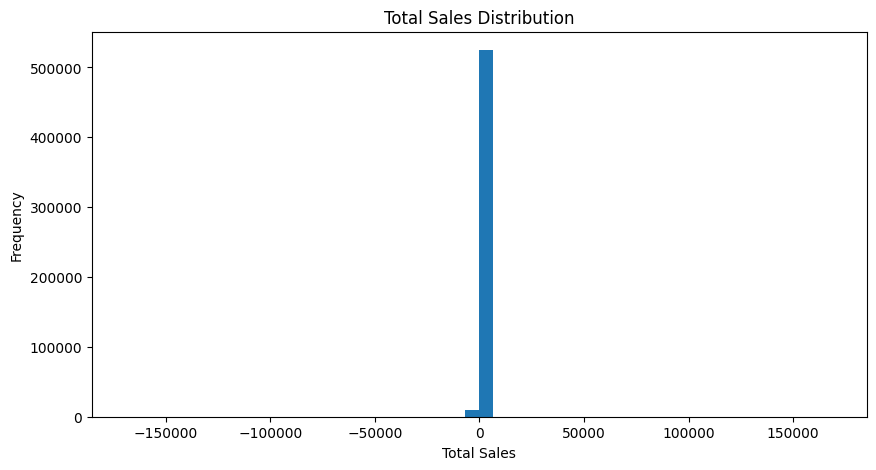

In [7]:
plt.figure(figsize=(10,5))

plt.hist(df['TotalSales'], bins=50)

plt.title('Total Sales Distribution')
plt.xlabel('Total Sales')
plt.ylabel('Frequency')

plt.show()

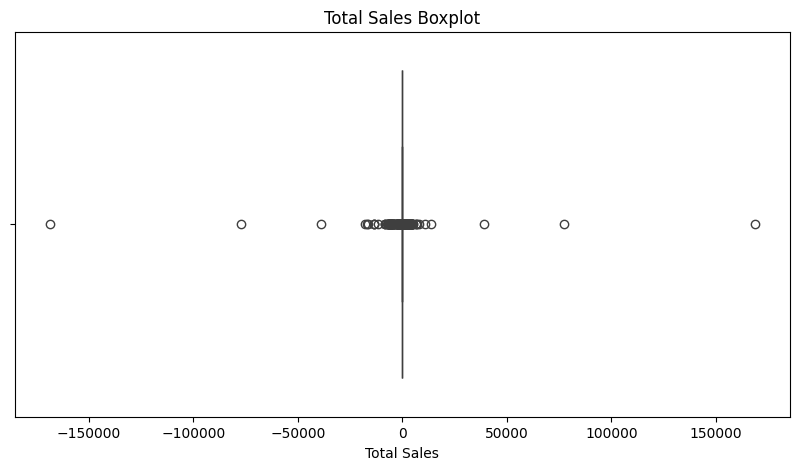

In [8]:
plt.figure(figsize=(10,5))

sns.boxplot(x=df['TotalSales'])

plt.title('Total Sales Boxplot')
plt.xlabel('Total Sales')

plt.show()

In [9]:
from scipy.stats import spearmanr

corr, p_value = spearmanr(
    df['Quantity'],
    df['TotalSales']
)

print("Correlation:", corr)
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: Significant relationship")
else:
    print("Result: No significant relationship")

Correlation: 0.6907006824511956
P-value: 0.0
Result: Significant relationship


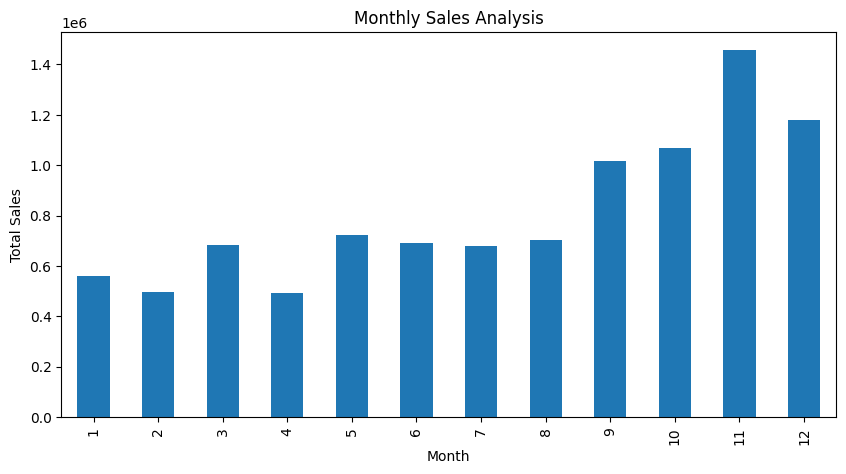

Month
1      558448.560
2      497026.410
3      682013.980
4      492367.841
5      722094.100
6      689977.230
7      680156.991
8      703510.580
9     1017596.682
10    1069368.230
11    1456145.800
12    1179424.670
Name: TotalSales, dtype: float64


In [10]:
monthly_sales = df.groupby('Month')['TotalSales'].sum()

monthly_sales.plot(kind='bar', figsize=(10,5))

plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.show()

print(monthly_sales)

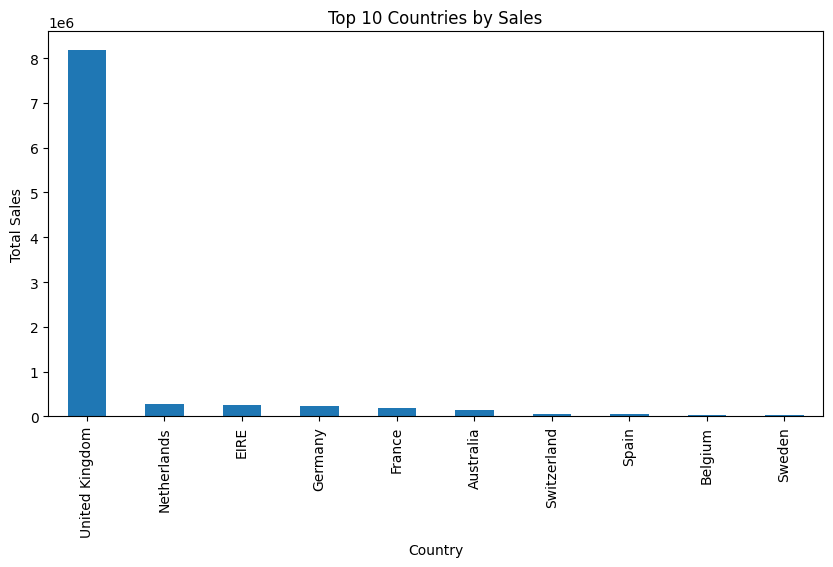

Country
United Kingdom    8189252.304
Netherlands        284661.540
EIRE               262993.380
Germany            221509.470
France             197317.110
Australia          137009.770
Switzerland         56363.050
Spain               54756.030
Belgium             40910.960
Sweden              36585.410
Name: TotalSales, dtype: float64


In [11]:
country_sales = df.groupby('Country')['TotalSales'].sum()

country_sales = country_sales.sort_values(
    ascending=False
).head(10)

country_sales.plot(kind='bar', figsize=(10,5))

plt.title("Top 10 Countries by Sales")
plt.xlabel("Country")
plt.ylabel("Total Sales")
plt.show()

print(country_sales)

In [12]:
from scipy.stats import kruskal

monthly_groups = [
    group['TotalSales'].values
    for _, group in df.groupby('Month')
]

stat, p = kruskal(*monthly_groups)

print("Kruskal-Wallis Statistic:", stat)
print("P-value:", p)

if p < 0.05:
    print("Significant difference in monthly sales")
else:
    print("No significant difference")

Kruskal-Wallis Statistic: 3113.7634009801614
P-value: 0.0
Significant difference in monthly sales


In [13]:
top_countries = df['Country'].value_counts().head(10).index

country_groups = [
    group['TotalSales'].values
    for _, group in df[df['Country'].isin(top_countries)].groupby('Country')
]

stat, p = kruskal(*country_groups)

print("Kruskal-Wallis Statistic:", stat)
print("P-value:", p)

if p < 0.05:
    print("Significant difference in country sales")
else:
    print("No significant difference")

Kruskal-Wallis Statistic: 21147.6353199108
P-value: 0.0
Significant difference in country sales


Statistical Hypothesis Testing Results

Hypothesis 1: Quantity vs TotalSales

- Spearman Correlation: 0.6907
- P-value: 0.0
- Result: Significant positive relationship between Quantity and TotalSales.

Hypothesis 2: Monthly Sales Differences

- Kruskal-Wallis Statistic: 3113.7634
- P-value: 0.0
- Result: Monthly sales distributions show a statistically significant difference.

Hypothesis 3: Country-wise Sales Differences

- Kruskal-Wallis Statistic: 21147.6353
- P-value: 0.0
- Result: Sales distributions differ significantly across countries.

Top 5 Critical Findings

1. Quantity has a strong positive relationship with TotalSales.
2. November recorded the highest monthly sales.
3. United Kingdom recorded the highest country-wise sales.
4. Sales distribution contains extreme values and outliers.
5. Monthly and country-wise sales distributions show statistically significant differences.

Conclusion

Exploratory Data Analysis revealed important business patterns in sales, quantity, monthly performance, and country-wise performance. Statistical testing confirmed significant differences in monthly and country-wise sales distributions. These insights can support better business decision-making.